# Procedural cell-counting workflows

The two procedural workflows compared in *Image-information limits to automated
cell counting across procedural and deep-learning workflows*, applied to the six
brightfield images of a suspension CHO culture in
[sample images/](sample%20images/).

Both variants run the same pipeline — grayscale conversion, percentile contrast
stretching, Gaussian smoothing, Otsu thresholding, binary closing and erosion
with a one-pixel disk, then 8-connected component labelling — and differ only in
the contrast limits and whether a minimum-area exclusion is applied:

| Workflow | Contrast limits | Smoothing | Threshold | Cleaning | Area exclusion |
|---|---|---|---|---|---|
| **scikit Bright** | 99th / 100th percentile | Gaussian, σ = 0.5 px | Otsu | closing + erosion, 1 px disk | none |
| **scikit Dim** | 98th / 99th percentile | Gaussian, σ = 0.5 px | Otsu | closing + erosion, 1 px disk | components < 80 px removed |

Neither is selected per image: both are applied to every image with fixed
settings and reported as two separate workflows. Image-specific percentile
adjustment was explored during development but deliberately not used.

The count is the number of connected components surviving the area rule.

This notebook covers the procedural workflows only. The deep-learning workflow
was run interactively in the [Cellpose GUI](https://github.com/mouseland/cellpose)
and has no script in this repository — see the README.

**Scope.** This notebook shows what each workflow produces. Parameter selection,
sensitivity analysis, and agreement against manual haemocytometer counts are
reported in the paper and are not repeated here. Note also that these six images
are **full frames**, whereas the paper's longitudinal analysis used cropped
fields — so the counts below are not the paper's numbers.

## 1. Setup

In [1]:
from pathlib import Path
import platform
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage
from skimage import color, exposure, filters, io, measure, morphology
from skimage.color import label2rgb

REPO_DIR = Path.cwd()
SAMPLE_DIR = REPO_DIR / "sample images"

if not SAMPLE_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find {SAMPLE_DIR}. Run this notebook from the repository "
        "root -- the directory containing the 'sample images' folder."
    )

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 9,
    "axes.titlesize": 9.5,
    "axes.titleweight": "regular",
    "image.cmap": "gray",
    "image.interpolation": "nearest",
})

print(f"Python       {sys.version.split()[0]} ({platform.system()} {platform.release()})")
print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"scikit-image {skimage.__version__}")
print(f"matplotlib   {mpl.__version__}")

Python       3.11.11 (Windows 10)
numpy        1.26.4
pandas       2.2.2
scikit-image 0.20.0
matplotlib   3.9.2


### Sample images

Six frames from a single suspension CHO culture (line S1) spanning 864–1352 h of
elapsed culture time. Elapsed times come from the acquisition log; the filenames
encode only the capture date and the camera frame number.

In [2]:
# Elapsed culture time per frame (hours), from the acquisition log.
SAMPLE_TIMEPOINTS = {
    "cho-sc s1 30-06 0909.jpg": 864,
    "cho-sc s1 06-07 0914.jpg": 1014,
    "cho-sc s1 10-07 0948.jpg": 1106,
    "cho-sc s1 13-07 1164.jpg": 1181,
    "cho-sc s1 17-07 1200.jpg": 1277,
    "cho-sc s1 20-07 1350.jpg": 1352,
}

sample_paths = sorted(SAMPLE_DIR.glob("*.jpg"), key=lambda p: SAMPLE_TIMEPOINTS[p.name])
missing = set(SAMPLE_TIMEPOINTS) - {p.name for p in sample_paths}
if missing:
    raise FileNotFoundError(f"Missing sample image(s): {sorted(missing)}")

images = {p.name: io.imread(p) for p in sample_paths}

pd.DataFrame([
    {
        "filename": name,
        "elapsed_h": SAMPLE_TIMEPOINTS[name],
        "width_px": img.shape[1],
        "height_px": img.shape[0],
        "channels": img.shape[2],
    }
    for name, img in images.items()
])

,filename,elapsed_h,width_px,height_px,channels
0,cho-sc s1 30-06 0909.jpg,864,1394,1374,3
1,cho-sc s1 06-07 0914.jpg,1014,1335,1324,3
2,cho-sc s1 10-07 0948.jpg,1106,1332,1328,3
3,cho-sc s1 13-07 1164.jpg,1181,1358,1358,3
4,cho-sc s1 17-07 1200.jpg,1277,1342,1303,3
5,cho-sc s1 20-07 1350.jpg,1352,1335,1329,3


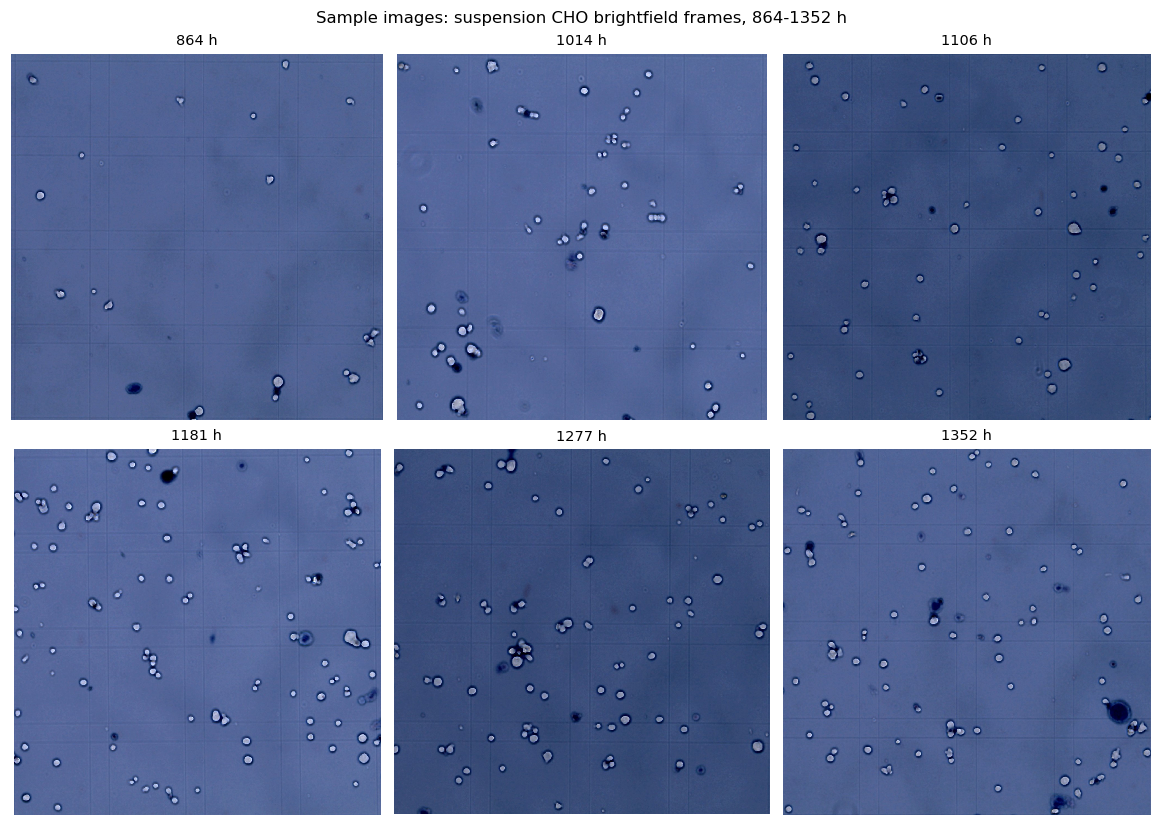

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 7.4), layout="constrained")
for ax, (name, img) in zip(axes.ravel(), images.items()):
    ax.imshow(img)
    ax.set_title(f"{SAMPLE_TIMEPOINTS[name]} h")
    ax.set_axis_off()
fig.suptitle("Sample images: suspension CHO brightfield frames, 864-1352 h")
plt.show()

## 2. The workflows

`count_scikit` implements the shared pipeline once; `BRIGHT` and `DIM` supply the
two settings.

In [4]:
BRIGHT = dict(min_percentile=99, max_percentile=100, min_area=None)
DIM = dict(min_percentile=98, max_percentile=99, min_area=80)

GAUSSIAN_SIGMA = 0.5
MORPH_FOOTPRINT = morphology.disk(1)
CONNECTIVITY = 2


def count_scikit(image, min_percentile, max_percentile, min_area=None):
    """Count cells with the procedural workflow.

    Parameters
    ----------
    image : ndarray
        RGB or grayscale image.
    min_percentile, max_percentile : float
        Intensity percentiles used as the contrast-stretching limits.
    min_area : int or None
        If given, connected components smaller than this many pixels are
        excluded from the count.

    Returns
    -------
    (count, labels) : (int, ndarray)
        The cell count and the label image containing only counted objects.
    """
    gray = color.rgb2gray(image) if image.ndim == 3 else image

    vmin, vmax = np.percentile(gray, (min_percentile, max_percentile))
    stretched = exposure.rescale_intensity(gray, in_range=(vmin, vmax))

    blurred = filters.gaussian(stretched, sigma=GAUSSIAN_SIGMA)
    binary = blurred > filters.threshold_otsu(blurred)

    binary = morphology.binary_closing(binary, MORPH_FOOTPRINT)
    binary = morphology.binary_erosion(binary, MORPH_FOOTPRINT)

    labels = measure.label(binary, connectivity=CONNECTIVITY)
    regions = measure.regionprops(labels)

    if min_area is not None:
        kept = [r for r in regions if r.area >= min_area]
        counted = np.zeros_like(labels)
        for region in kept:
            counted[labels == region.label] = region.label
        return len(kept), counted

    return len(regions), labels


def count_bright(image):
    """scikit Bright: 99th/100th percentile limits, no area exclusion."""
    return count_scikit(image, **BRIGHT)


def count_dim(image):
    """scikit Dim: 98th/99th percentile limits, components below 80 px excluded."""
    return count_scikit(image, **DIM)

## 3. Counts

Both workflows applied to all six images, with fixed settings throughout.

In [5]:
WORKFLOWS = ["scikit Bright", "scikit Dim"]

labels_by_workflow = {}
rows = []

for name, img in images.items():
    bright_count, bright_labels = count_bright(img)
    dim_count, dim_labels = count_dim(img)

    labels_by_workflow[name] = {
        "scikit Bright": bright_labels,
        "scikit Dim": dim_labels,
    }
    rows.append({
        "filename": name,
        "elapsed_h": SAMPLE_TIMEPOINTS[name],
        "scikit Bright": bright_count,
        "scikit Dim": dim_count,
    })

counts = pd.DataFrame(rows)
counts

,filename,elapsed_h,scikit Bright,scikit Dim
0,cho-sc s1 30-06 0909.jpg,864,20,26
1,cho-sc s1 06-07 0914.jpg,1014,56,51
2,cho-sc s1 10-07 0948.jpg,1106,63,56
3,cho-sc s1 13-07 1164.jpg,1181,129,100
4,cho-sc s1 17-07 1200.jpg,1277,105,75
5,cho-sc s1 20-07 1350.jpg,1352,115,81


### Segmentation output

One row per image, one column per workflow. Each panel overlays the counted
objects on the grayscale image, so a count can be checked against what was
actually labelled.

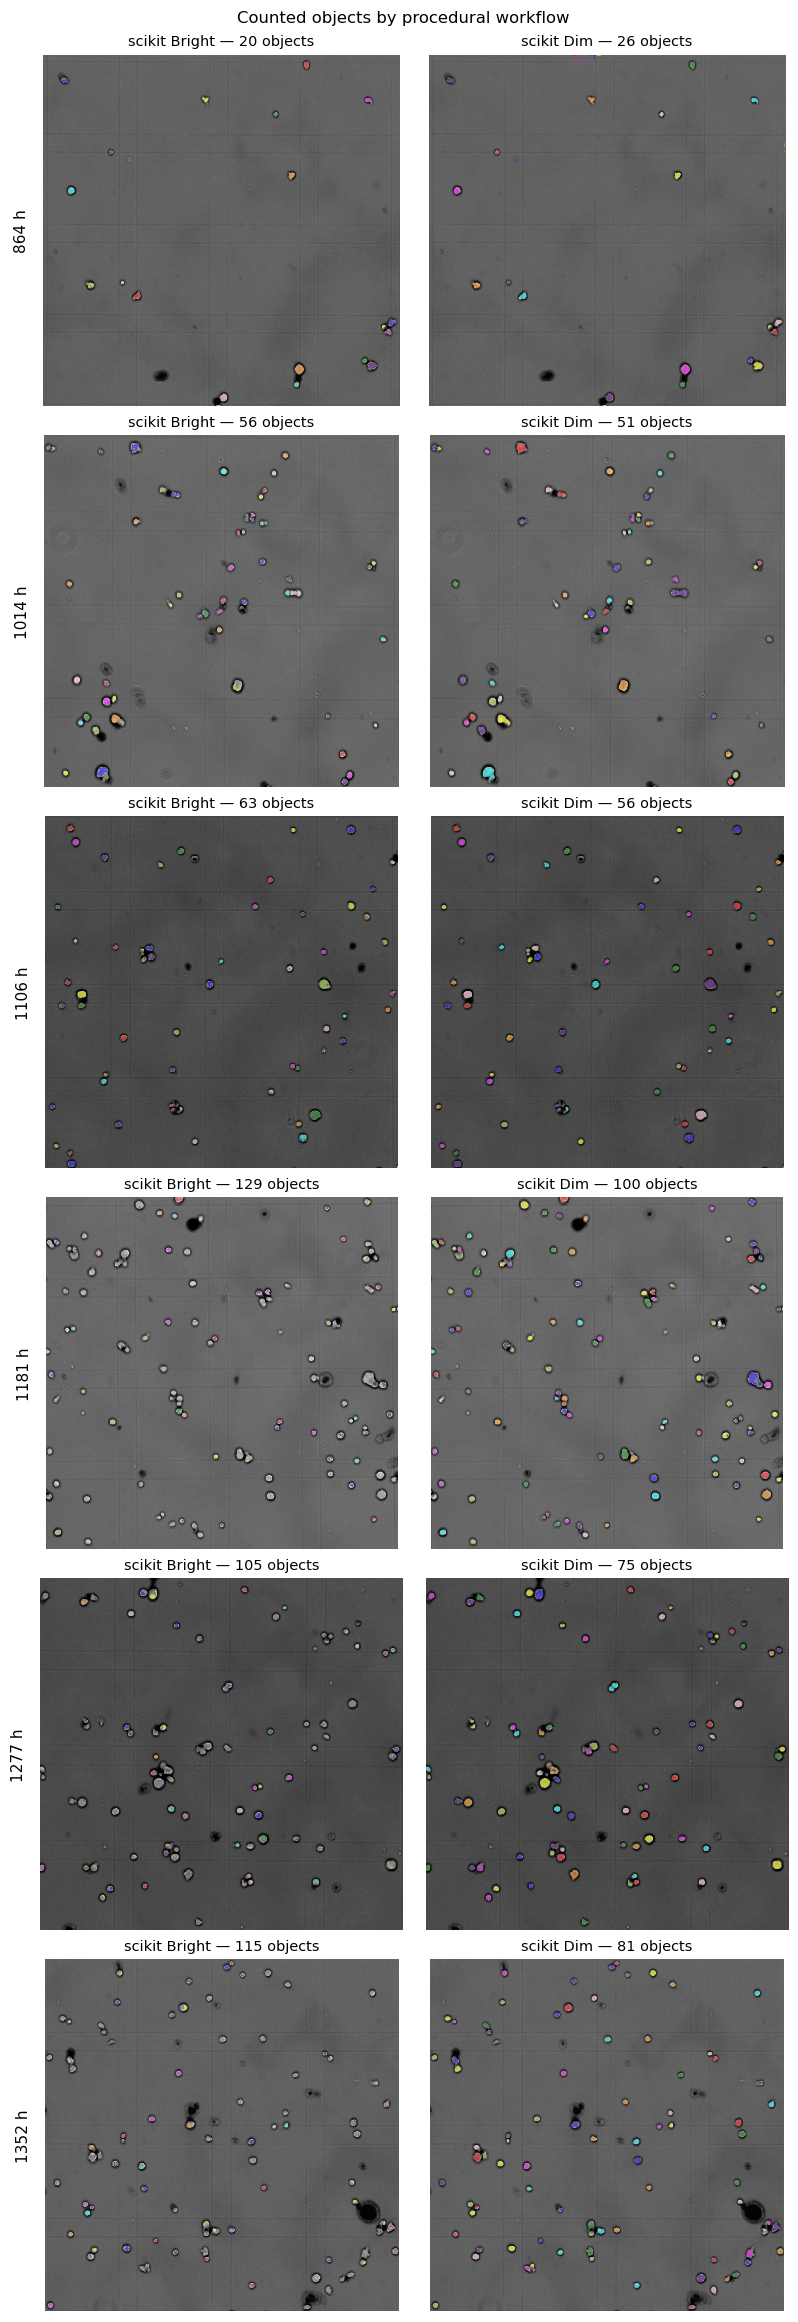

In [6]:
fig, axes = plt.subplots(len(images), len(WORKFLOWS),
                         figsize=(3.6 * len(WORKFLOWS), 3.5 * len(images)),
                         layout="constrained")

for row, (name, img) in zip(axes, images.items()):
    gray = color.rgb2gray(img)
    for ax, workflow in zip(row, WORKFLOWS):
        labels = labels_by_workflow[name][workflow]
        count = counts.loc[counts["filename"] == name, workflow].iat[0]
        ax.imshow(label2rgb(labels, image=gray, bg_label=0, alpha=0.5, bg_color=None))
        ax.set_title(f"{workflow} — {count} objects")
        ax.set_axis_off()

# Row labels: the axes have their frames off, so ylabel would not render.
for ax, name in zip(axes[:, 0], images):
    ax.text(-0.04, 0.5, f"{SAMPLE_TIMEPOINTS[name]} h", transform=ax.transAxes,
            rotation=90, va="center", ha="right", fontsize=10)

fig.suptitle("Counted objects by procedural workflow")
plt.show()

## Notes

- **The two variants are not alternatives to choose between per image.** Both are
  applied to every image with fixed settings and reported separately.

- **The area exclusion is what makes scikit Dim usable at low density.** At
  864 h the 98th-percentile contrast limit falls inside the background rather
  than above it, and the mask fills with sub-cell speckle; without the 80 px
  exclusion that frame yields 673 components instead of 26. scikit Bright's
  higher contrast limits avoid the problem without needing an area rule, which
  is why it has none.

- **These are full frames, not the paper's crops.** The longitudinal analysis in
  the paper used cropped fields; counts here will not match the values in its
  tables and are not intended to.

- **Parameter selection and sensitivity are out of scope here.** The choice of
  grayscale representation, smoothing method, thresholding rule and contrast
  limits is documented in the paper and its supplementary materials.